# Session 1- Grayscale Image Fundamentals 

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Image Height: 500
Image Width: 500
Number of Pixels: 250000
Datatype: uint8
Minimum Pixel Intensity: 22
Maximum Pixel Intensity: 246
Mean Pixel Intensity: 123.050168
Pixel Value at ( 100 , 100 ): 103


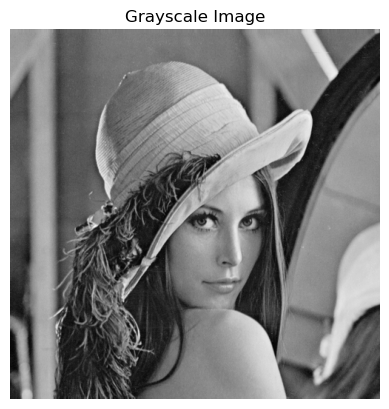

In [2]:
image_path = "Lenna.png"

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image could not be loaded.")
else:
    # a. Image height and width
    height, width = img.shape
    print("Image Height:", height)
    print("Image Width:", width)

    # b. Number of pixels
    number_of_pixels = img.size
    print("Number of Pixels:", number_of_pixels)

    # c. Datatype
    datatype = img.dtype
    print("Datatype:", datatype)

    # d. Minimum pixel intensity
    min_intensity = np.min(img)
    print("Minimum Pixel Intensity:", min_intensity)

    # e. Maximum pixel intensity
    max_intensity = np.max(img)
    print("Maximum Pixel Intensity:", max_intensity)

    # f. Mean pixel intensity
    mean_intensity = np.mean(img)
    print("Mean Pixel Intensity:", mean_intensity)

    # g. Pixel value at a specified coordinate
    x = 100
    y = 100

    if 0 <= x < width and 0 <= y < height:
        print("Pixel Value at (", x, ",", y, "):", img[y, x])
    else:
        print("Specified coordinate is outside the image.")

    cv2.imshow("Grayscale Image", img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

    plt.imshow(img, cmap="gray")
    plt.title("Grayscale Image")
    plt.axis("off")
    plt.show()

### Q2. Pixel-Level Operations

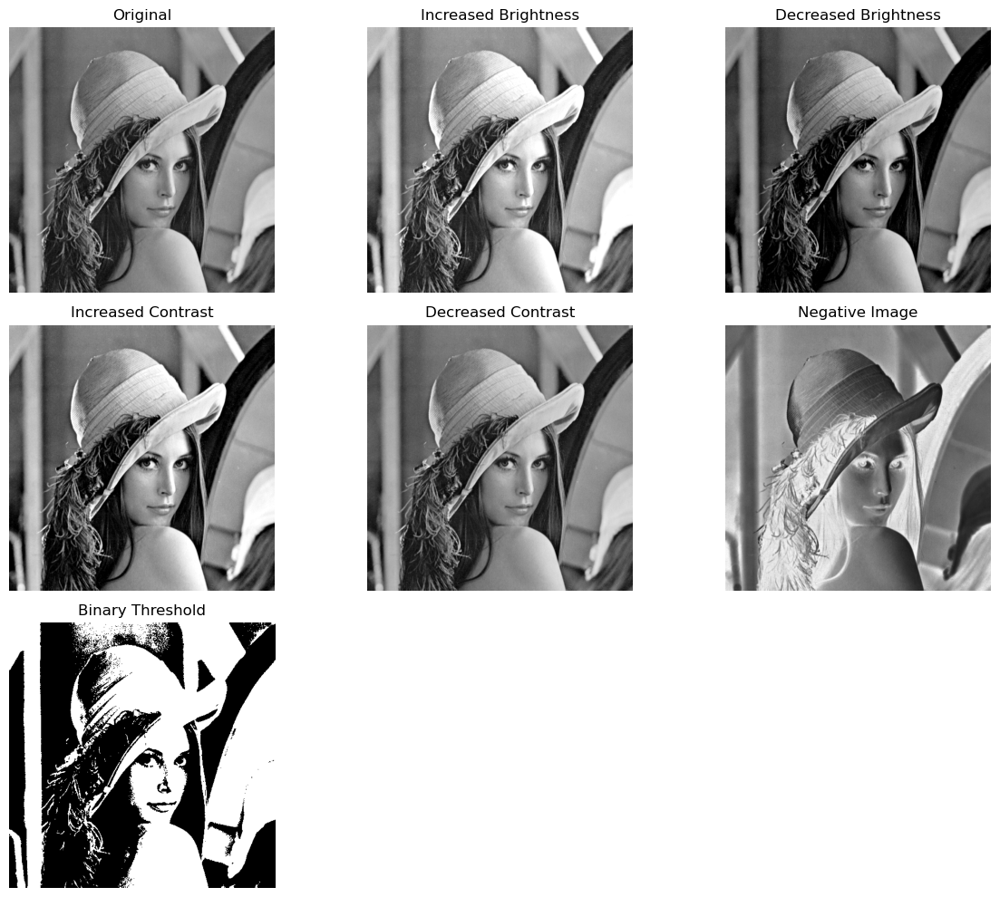

In [3]:
image_path = "Lenna.png"

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image could not be loaded.")
else:
    # a. Increase brightness
    increase_brightness = np.clip(
        img.astype(np.int16) + 50, 0, 255
    ).astype(np.uint8)

    # b. Decrease brightness
    decrease_brightness = np.clip(
        img.astype(np.int16) - 50, 0, 255
    ).astype(np.uint8)

    # c. Increase contrast
    increase_contrast = np.clip(
        128 + 1.5 * (img.astype(np.float32) - 128),
        0,
        255
    ).astype(np.uint8)

    # d. Decrease contrast
    decrease_contrast = np.clip(
        128 + 0.5 * (img.astype(np.float32) - 128),
        0,
        255
    ).astype(np.uint8)

    # e. Generate negative image
    negative = 255 - img

    # f. Apply binary thresholding
    threshold = np.where(img >= 127, 255, 0).astype(np.uint8)

    images = [
        ("Original", img),
        ("Increased Brightness", increase_brightness),
        ("Decreased Brightness", decrease_brightness),
        ("Increased Contrast", increase_contrast),
        ("Decreased Contrast", decrease_contrast),
        ("Negative Image", negative),
        ("Binary Threshold", threshold)
    ]

    plt.figure(figsize=(12, 10))

    for i, (title, image) in enumerate(images):
        plt.subplot(3, 3, i + 1)
        plt.imshow(image, cmap="gray")
        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# Session 2: Image Formation, Transformation and Resampling

### Q1. Geometric Transformations

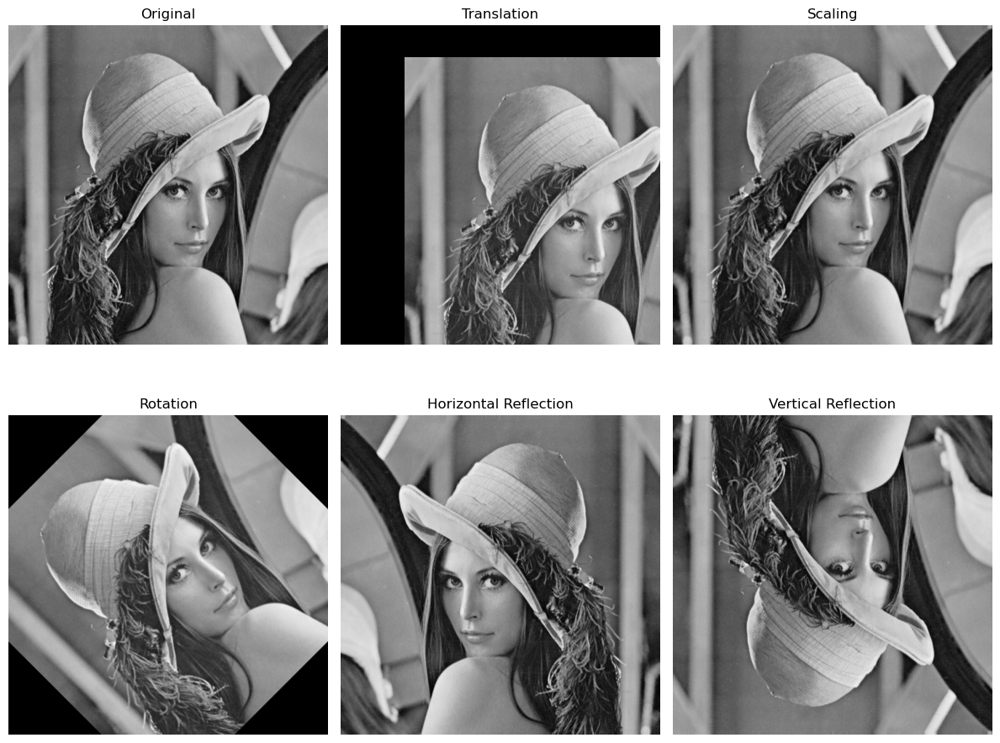

In [6]:
image_path = "Lenna.png"

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image could not be loaded.")
else:
    height, width = img.shape

    # a. Translation
    translation_matrix = np.float32([
        [1, 0, 100],
        [0, 1, 50]
    ])

    translated = cv2.warpAffine(
        img,
        translation_matrix,
        (width, height)
    )

    # b. Scaling
    scaled = cv2.resize(
        img,
        None,
        fx=1.5,
        fy=1.5,
        interpolation=cv2.INTER_LINEAR
    )

    # c. Rotation
    center = (width // 2, height // 2)

    rotation_matrix = cv2.getRotationMatrix2D(
        center,
        45,
        1.0
    )

    rotated = cv2.warpAffine(
        img,
        rotation_matrix,
        (width, height)
    )

    # d. Horizontal reflection
    horizontal_reflection_matrix = np.float32([
        [-1, 0, width - 1],
        [0, 1, 0]
    ])

    horizontal_reflection = cv2.warpAffine(
        img,
        horizontal_reflection_matrix,
        (width, height)
    )

    # e. Vertical reflection
    vertical_reflection_matrix = np.float32([
        [1, 0, 0],
        [0, -1, height - 1]
    ])

    vertical_reflection = cv2.warpAffine(
        img,
        vertical_reflection_matrix,
        (width, height)
    )

    images = [
        ("Original", img),
        ("Translation", translated),
        ("Scaling", scaled),
        ("Rotation", rotated),
        ("Horizontal Reflection", horizontal_reflection),
        ("Vertical Reflection", vertical_reflection)
    ]

    plt.figure(figsize=(12, 10))

    for i, (title, image) in enumerate(images):
        plt.subplot(2, 3, i + 1)
        plt.imshow(image, cmap="gray")
        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

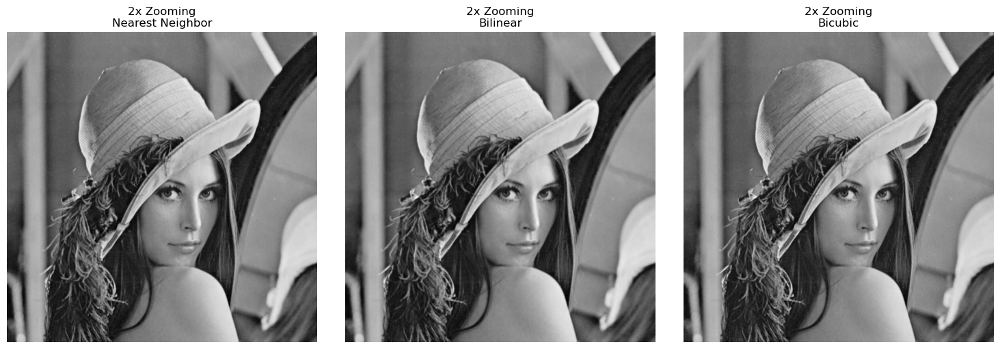

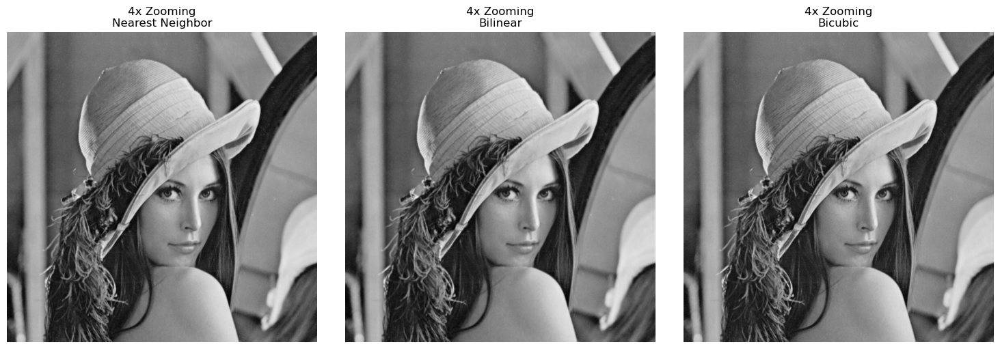

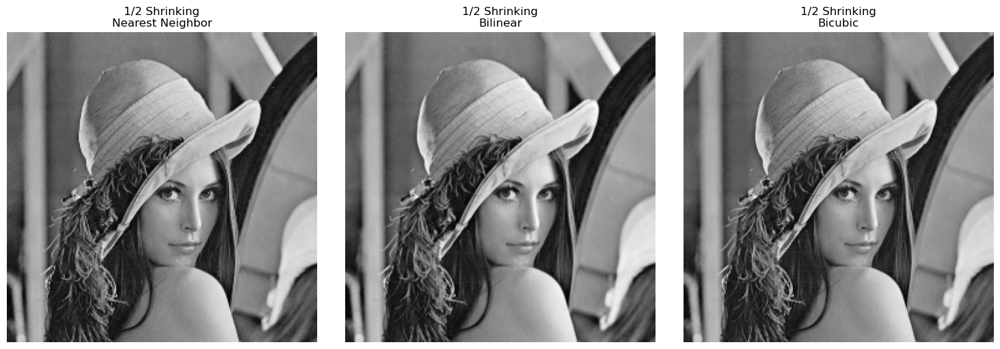

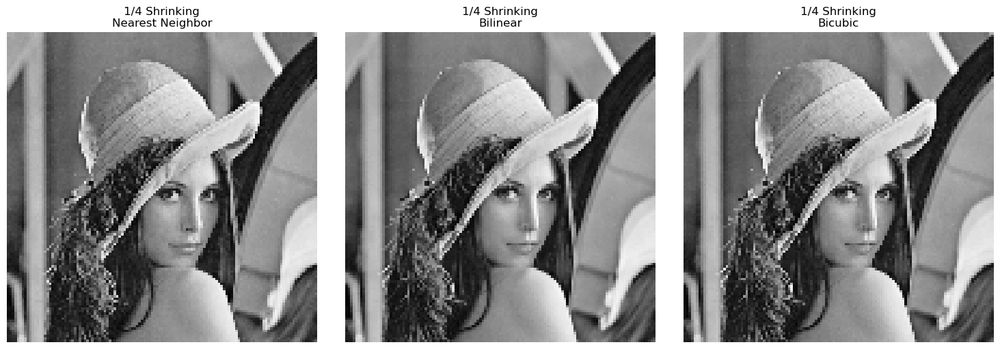

In [7]:
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image could not be loaded.")
else:
    # a. Nearest-neighbor interpolation
    # b. Bilinear interpolation
    # c. Bicubic interpolation
    methods = {
        "Nearest Neighbor": cv2.INTER_NEAREST,
        "Bilinear": cv2.INTER_LINEAR,
        "Bicubic": cv2.INTER_CUBIC
    }

    scales = {
        "2x Zooming": 2.0,
        "4x Zooming": 4.0,
        "1/2 Shrinking": 0.5,
        "1/4 Shrinking": 0.25
    }

    for scale_name, scale in scales.items():
        results = []

        for method_name, interpolation in methods.items():
            resized = cv2.resize(
                img,
                None,
                fx=scale,
                fy=scale,
                interpolation=interpolation
            )

            results.append((method_name, resized))

        plt.figure(figsize=(15, 5))

        for i, (method_name, image) in enumerate(results):
            plt.subplot(1, 3, i + 1)
            plt.imshow(image, cmap="gray")
            plt.title(scale_name + "\n" + method_name)
            plt.axis("off")

        plt.tight_layout()
        plt.show()

# Session 3— Mathematical Foundations of Image Processing

### Q1. Pixel Relationships, Connectivity and Distance Measures

Binary Image:
[[0 0 1 1 0 0]
 [0 1 1 1 0 0]
 [0 0 1 0 0 1]
 [0 0 0 0 1 1]
 [1 1 0 0 0 0]
 [1 1 0 0 0 0]]

Selected Pixels:
P = (1, 2)
Q = (2, 5)

4-neighbour Connectivity:
False

8-neighbour Connectivity:
False

m-connectivity:
False

Euclidean Distance:
3.1622776601683795

City-block Distance:
4

Chessboard Distance:
3


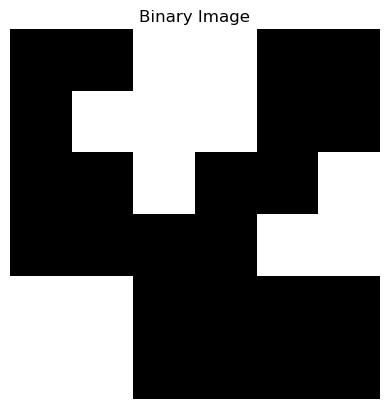

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import math

# Suitable binary image
binary = np.array([
    [0, 0, 1, 1, 0, 0],
    [0, 1, 1, 1, 0, 0],
    [0, 0, 1, 0, 0, 1],
    [0, 0, 0, 0, 1, 1],
    [1, 1, 0, 0, 0, 0],
    [1, 1, 0, 0, 0, 0]
], dtype=np.uint8)

# Selected pixels
p = (1, 2)
q = (2, 5)

# --------------------------------------------------
# a. 4-neighbour connectivity
# --------------------------------------------------

four_neighbours = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1)
]

# --------------------------------------------------
# b. 8-neighbour connectivity
# --------------------------------------------------

eight_neighbours = [
    (-1, -1), (-1, 0), (-1, 1),
    (0, -1),           (0, 1),
    (1, -1),  (1, 0),  (1, 1)
]

# --------------------------------------------------
# c. m-connectivity
# --------------------------------------------------

def m_neighbours(image, pixel):

    r, c = pixel
    result = []

    for dr, dc in eight_neighbours:

        nr = r + dr
        nc = c + dc

        if 0 <= nr < image.shape[0] and 0 <= nc < image.shape[1]:

            if image[nr, nc] == 1:

                # Direct 4-neighbour
                if dr == 0 or dc == 0:
                    result.append((nr, nc))

                # Diagonal neighbour
                else:
                    common = []

                    if 0 <= r < image.shape[0] and 0 <= nc < image.shape[1]:
                        common.append(image[r, nc])

                    if 0 <= nr < image.shape[0] and 0 <= c < image.shape[1]:
                        common.append(image[nr, c])

                    # Diagonal connection only if common 4-neighbours
                    # are not object pixels
                    if not any(common):
                        result.append((nr, nc))

    return result


# --------------------------------------------------
# Connectivity checking
# --------------------------------------------------

def is_connected(image, start, end, connectivity):

    if image[start] == 0 or image[end] == 0:
        return False

    visited = set()
    queue = deque([start])

    while queue:

        current = queue.popleft()

        if current == end:
            return True

        if current in visited:
            continue

        visited.add(current)

        r, c = current

        if connectivity == 4:
            neighbours = four_neighbours

        elif connectivity == 8:
            neighbours = eight_neighbours

        elif connectivity == 'm':
            neighbours = m_neighbours(image, current)
            neighbours = [
                (nr - r, nc - c)
                for nr, nc in neighbours
            ]

        for dr, dc in neighbours:

            nr = r + dr
            nc = c + dc

            if (0 <= nr < image.shape[0] and
                0 <= nc < image.shape[1]):

                if image[nr, nc] == 1:
                    if (nr, nc) not in visited:
                        queue.append((nr, nc))

    return False


print("Binary Image:")
print(binary)

print("\nSelected Pixels:")
print("P =", p)
print("Q =", q)

print("\n4-neighbour Connectivity:")
print(is_connected(binary, p, q, 4))

print("\n8-neighbour Connectivity:")
print(is_connected(binary, p, q, 8))

print("\nm-connectivity:")
print(is_connected(binary, p, q, 'm'))


# --------------------------------------------------
# d. Euclidean distance
# --------------------------------------------------

euclidean = math.sqrt(
    (p[0] - q[0]) ** 2 +
    (p[1] - q[1]) ** 2
)

print("\nEuclidean Distance:")
print(euclidean)


# --------------------------------------------------
# e. City-block distance
# --------------------------------------------------

city_block = (
    abs(p[0] - q[0]) +
    abs(p[1] - q[1])
)

print("\nCity-block Distance:")
print(city_block)


# --------------------------------------------------
# f. Chessboard distance
# --------------------------------------------------

chessboard = max(
    abs(p[0] - q[0]),
    abs(p[1] - q[1])
)

print("\nChessboard Distance:")
print(chessboard)


# --------------------------------------------------
# Display binary image
# --------------------------------------------------

plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()

### Q2. DFT and DCT

DFT calculated successfully.

DCT Coefficient Matrix:
[[61525.08 -5092.85 -1187.98 ...     0.9      3.52    -2.41]
 [ 3468.49  3809.63 -3171.45 ...     2.86    -3.37    -1.55]
 [ -102.55  1519.58 -2924.81 ...     4.27    -4.28    -4.36]
 ...
 [    6.87    -2.15     2.25 ...    -0.44    -1.28     1.4 ]
 [   -3.26     2.48     1.9  ...     0.46     1.29     0.4 ]
 [   -0.1      3.13    -2.21 ...     0.67     0.04     0.56]]


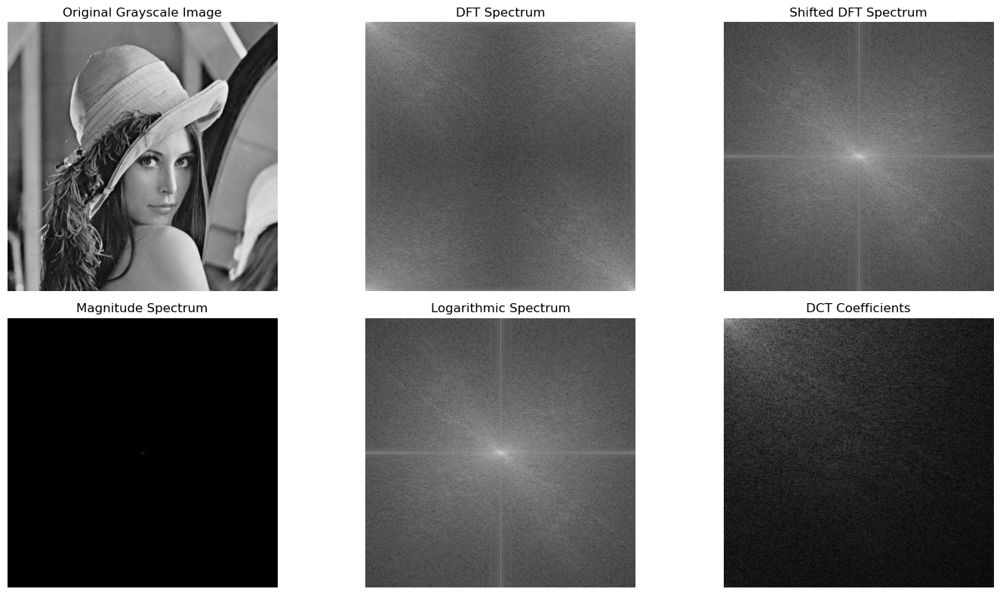

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("Lenna.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found.")
    exit()

# --------------------------------------------------
# a. Calculate 2-D Discrete Fourier Transform (DFT)
# --------------------------------------------------

dft = np.fft.fft2(img)

print("DFT calculated successfully.")

# --------------------------------------------------
# b. Shift zero-frequency component to center
# --------------------------------------------------

dft_shifted = np.fft.fftshift(dft)

# --------------------------------------------------
# c. Calculate magnitude spectrum
# --------------------------------------------------

magnitude = np.abs(dft_shifted)

# --------------------------------------------------
# d. Apply logarithmic scaling
# --------------------------------------------------

log_magnitude = np.log(1 + magnitude)

# Normalize for display
log_magnitude_display = cv2.normalize(
    log_magnitude,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

log_magnitude_display = np.uint8(log_magnitude_display)

# --------------------------------------------------
# e. Calculate 2-D Discrete Cosine Transform (DCT)
# --------------------------------------------------

img_float = np.float32(img)

dct = cv2.dct(img_float)

# --------------------------------------------------
# f. Display DCT coefficient matrix
# --------------------------------------------------

print("\nDCT Coefficient Matrix:")
np.set_printoptions(precision=2, suppress=True)
print(dct)


# --------------------------------------------------
# Display results
# --------------------------------------------------

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(np.log(1 + np.abs(dft)), cmap="gray")
plt.title("DFT Spectrum")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(np.log(1 + np.abs(dft_shifted)), cmap="gray")
plt.title("Shifted DFT Spectrum")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(magnitude, cmap="gray")
plt.title("Magnitude Spectrum")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(log_magnitude_display, cmap="gray")
plt.title("Logarithmic Spectrum")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(np.log(1 + np.abs(dct)), cmap="gray")
plt.title("DCT Coefficients")
plt.axis("off")

plt.tight_layout()
plt.show()

# SESSION 4 — Histogram Processing and Contrast Enhancement

### Q1. Histogram and CDF of a Grayscale Image

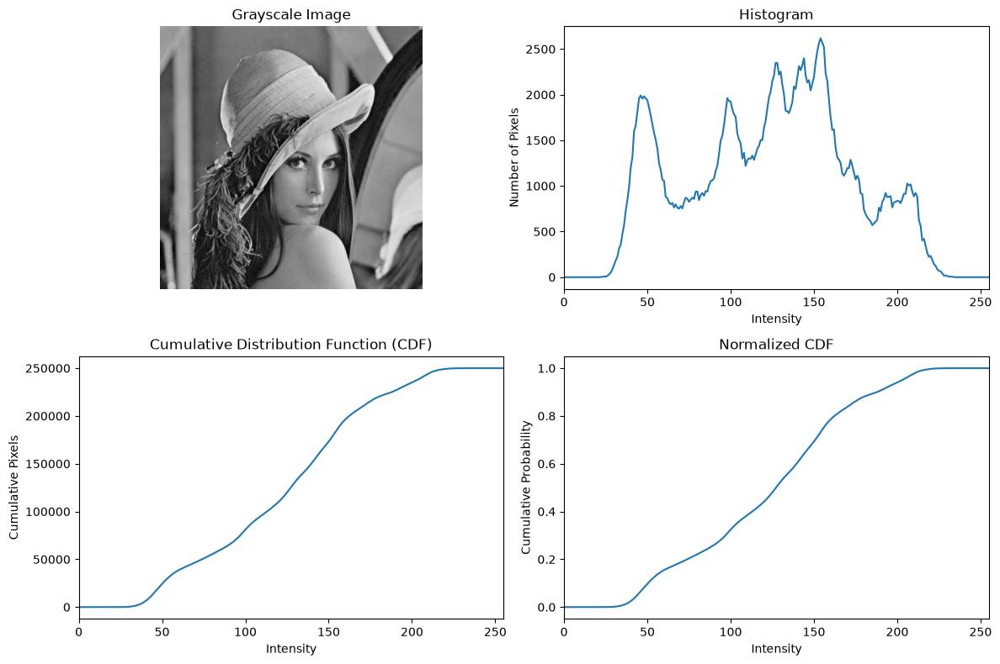

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Read grayscale image
# --------------------------------------------------

img = cv2.imread("Lenna.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")
    exit()


# --------------------------------------------------
# Function to calculate histogram and CDF
# --------------------------------------------------

def calculate_histogram_cdf(image):

    # Histogram
    histogram = np.bincount(
        image.ravel(),
        minlength=256
    )

    # CDF
    cdf = histogram.cumsum()

    return histogram, cdf


# Calculate
histogram, cdf = calculate_histogram_cdf(img)


# --------------------------------------------------
# Display image, histogram and CDF
# --------------------------------------------------

plt.figure(figsize=(12, 8))

# Original image
plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

# Histogram
plt.subplot(2, 2, 2)
plt.plot(histogram)
plt.title("Histogram")
plt.xlabel("Intensity")
plt.ylabel("Number of Pixels")
plt.xlim([0, 255])

# CDF
plt.subplot(2, 2, 3)
plt.plot(cdf)
plt.title("Cumulative Distribution Function (CDF)")
plt.xlabel("Intensity")
plt.ylabel("Cumulative Pixels")
plt.xlim([0, 255])

# Normalized CDF
normalized_cdf = cdf / cdf[-1]

plt.subplot(2, 2, 4)
plt.plot(normalized_cdf)
plt.title("Normalized CDF")
plt.xlabel("Intensity")
plt.ylabel("Cumulative Probability")
plt.xlim([0, 255])

plt.tight_layout()
plt.show()

### Q2. Contrast Enhancement

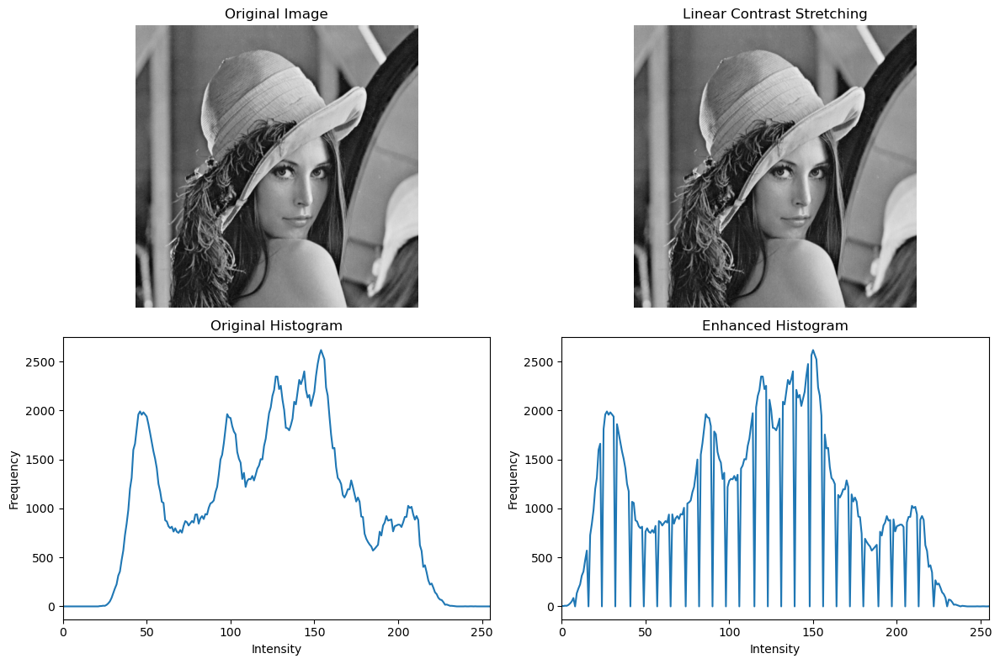

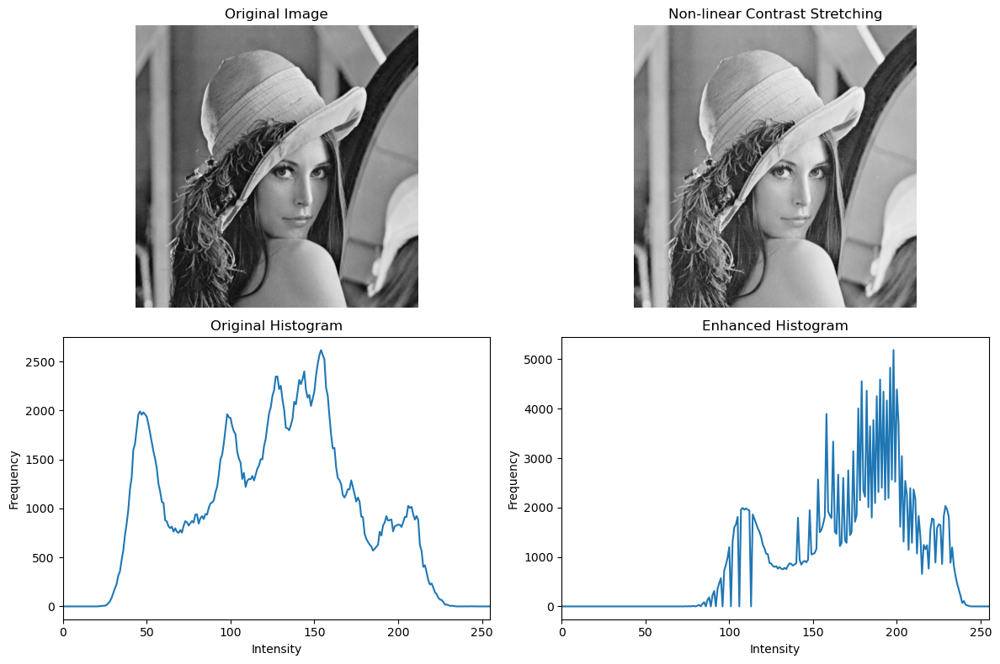

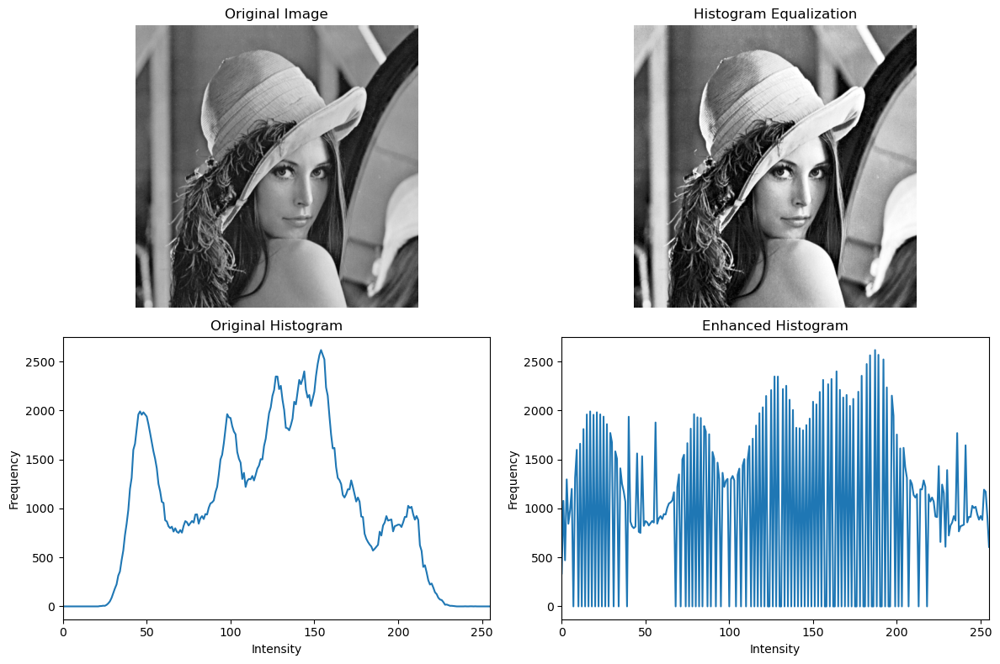

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Read grayscale image
# --------------------------------------------------

img = cv2.imread("Lenna.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")
    exit()


# --------------------------------------------------
# Function to calculate histogram
# --------------------------------------------------

def get_histogram(image):

    return np.bincount(
        image.ravel(),
        minlength=256
    )


# --------------------------------------------------
# 1. Linear Contrast Stretching
# --------------------------------------------------

def linear_contrast_stretch(image):

    r_min = np.min(image)
    r_max = np.max(image)

    if r_max == r_min:
        return image.copy()

    stretched = (
        (image.astype(np.float32) - r_min)
        * 255
        / (r_max - r_min)
    )

    return np.uint8(stretched)


linear = linear_contrast_stretch(img)


# --------------------------------------------------
# 2. Non-linear Contrast Stretching
# --------------------------------------------------

# Gamma transformation
gamma = 0.5

normalized = img / 255.0

nonlinear = (
    255 * np.power(normalized, gamma)
).astype(np.uint8)


# --------------------------------------------------
# 3. Histogram Equalization
# --------------------------------------------------

equalized = cv2.equalizeHist(img)


# --------------------------------------------------
# Function to display result
# --------------------------------------------------

def display_result(original, enhanced, title):

    original_hist = get_histogram(original)
    enhanced_hist = get_histogram(enhanced)

    plt.figure(figsize=(12, 8))

    # Original image
    plt.subplot(2, 2, 1)
    plt.imshow(original, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    # Enhanced image
    plt.subplot(2, 2, 2)
    plt.imshow(enhanced, cmap="gray")
    plt.title(title)
    plt.axis("off")

    # Original histogram
    plt.subplot(2, 2, 3)
    plt.plot(original_hist)
    plt.title("Original Histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Frequency")
    plt.xlim([0, 255])

    # Enhanced histogram
    plt.subplot(2, 2, 4)
    plt.plot(enhanced_hist)
    plt.title("Enhanced Histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Frequency")
    plt.xlim([0, 255])

    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# Display all three techniques
# --------------------------------------------------

display_result(
    img,
    linear,
    "Linear Contrast Stretching"
)

display_result(
    img,
    nonlinear,
    "Non-linear Contrast Stretching"
)

display_result(
    img,
    equalized,
    "Histogram Equalization"
)

# SESSION 5 — Spatial-Domain Filtering and Non-linear Filtering

### Q1. Add Noise and Apply Spatial-Domain Smoothing

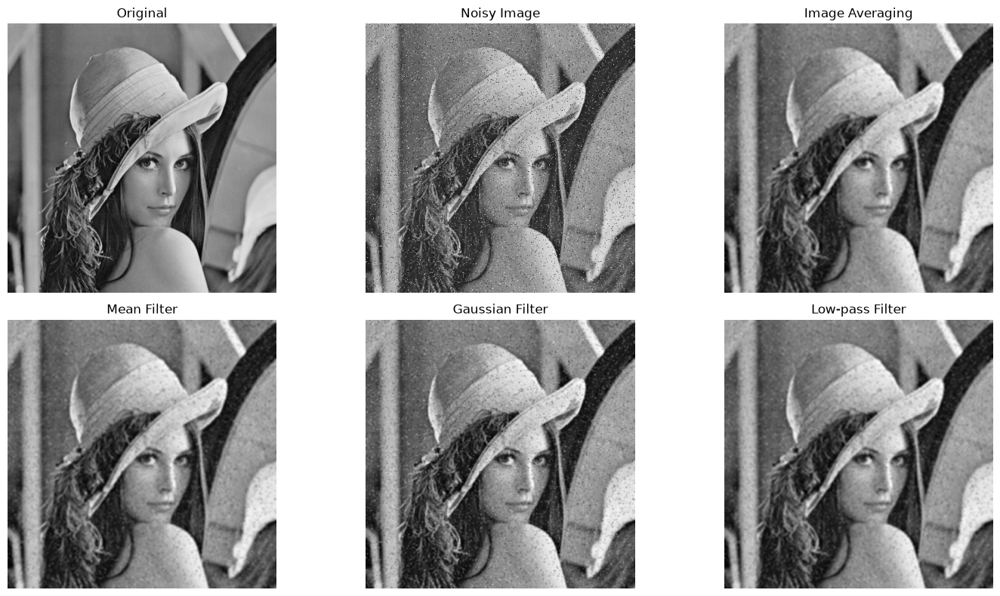

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# --------------------------------------------------
# Read grayscale image
# --------------------------------------------------

img = cv2.imread(
    "Lenna.png",
    cv2.IMREAD_GRAYSCALE
)

if img is None:
    print("Image not found!")
    exit()


# --------------------------------------------------
# Add Salt-and-Pepper Noise
# --------------------------------------------------

def add_salt_pepper_noise(image, amount=0.05):

    noisy = image.copy()

    total_pixels = image.size

    number_of_noisy_pixels = int(
        amount * total_pixels
    )

    # Salt noise
    salt_indices = np.random.randint(
        0,
        image.shape[0],
        number_of_noisy_pixels // 2
    )

    salt_indices_x = np.random.randint(
        0,
        image.shape[1],
        number_of_noisy_pixels // 2
    )

    noisy[
        salt_indices,
        salt_indices_x
    ] = 255

    # Pepper noise
    pepper_indices = np.random.randint(
        0,
        image.shape[0],
        number_of_noisy_pixels // 2
    )

    pepper_indices_x = np.random.randint(
        0,
        image.shape[1],
        number_of_noisy_pixels // 2
    )

    noisy[
        pepper_indices,
        pepper_indices_x
    ] = 0

    return noisy


noisy = add_salt_pepper_noise(img, 0.05)


# --------------------------------------------------
# Kernel size
# --------------------------------------------------

kernel_size = (5, 5)


# --------------------------------------------------
# a. Image Averaging
# --------------------------------------------------

kernel = np.ones(kernel_size, np.float32) / 25

averaged = cv2.filter2D(
    noisy,
    -1,
    kernel
)


# --------------------------------------------------
# b. Mean Filter
# --------------------------------------------------

mean_filtered = cv2.blur(
    noisy,
    kernel_size
)


# --------------------------------------------------
# c. Gaussian Filter
# --------------------------------------------------

gaussian = cv2.GaussianBlur(
    noisy,
    kernel_size,
    0
)


# --------------------------------------------------
# d. Low-pass Filter
# --------------------------------------------------

low_pass_kernel = np.ones(
    kernel_size,
    np.float32
) / 25

low_pass = cv2.filter2D(
    noisy,
    -1,
    low_pass_kernel
)


# --------------------------------------------------
# Display
# --------------------------------------------------

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(noisy, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(averaged, cmap="gray")
plt.title("Image Averaging")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(mean_filtered, cmap="gray")
plt.title("Mean Filter")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(low_pass, cmap="gray")
plt.title("Low-pass Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

### Q2. Non-linear Filters

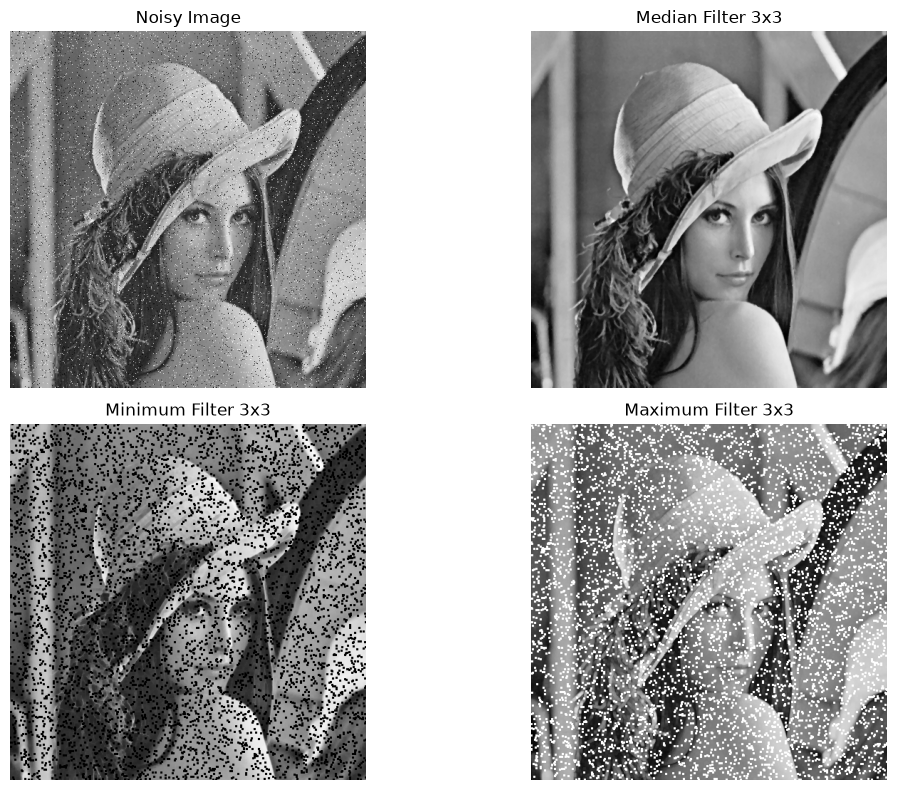

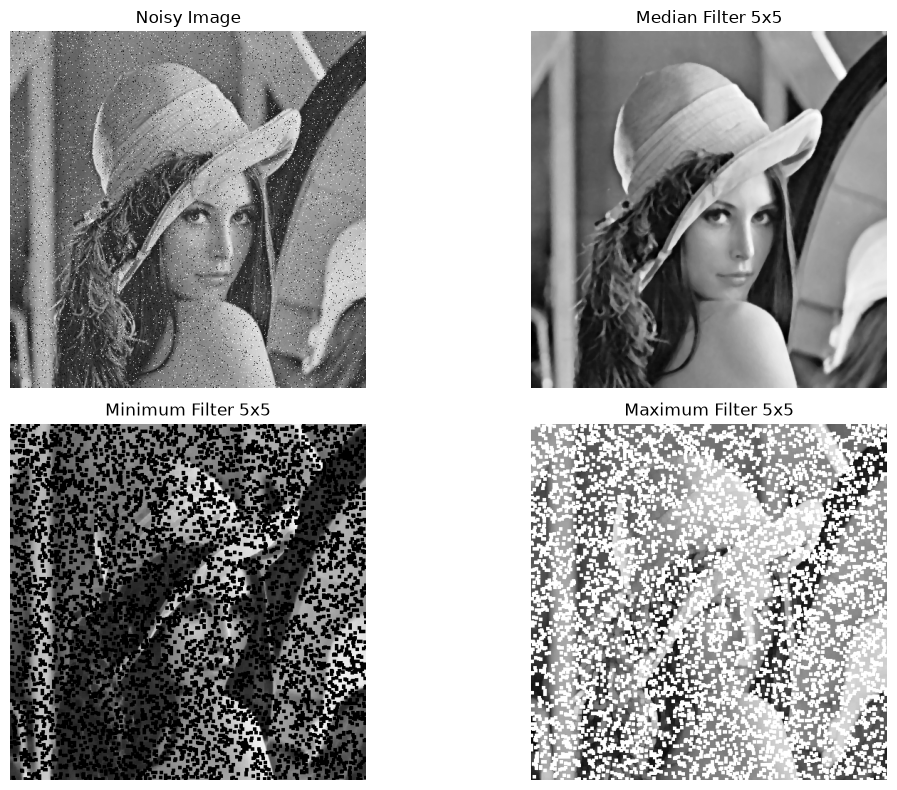

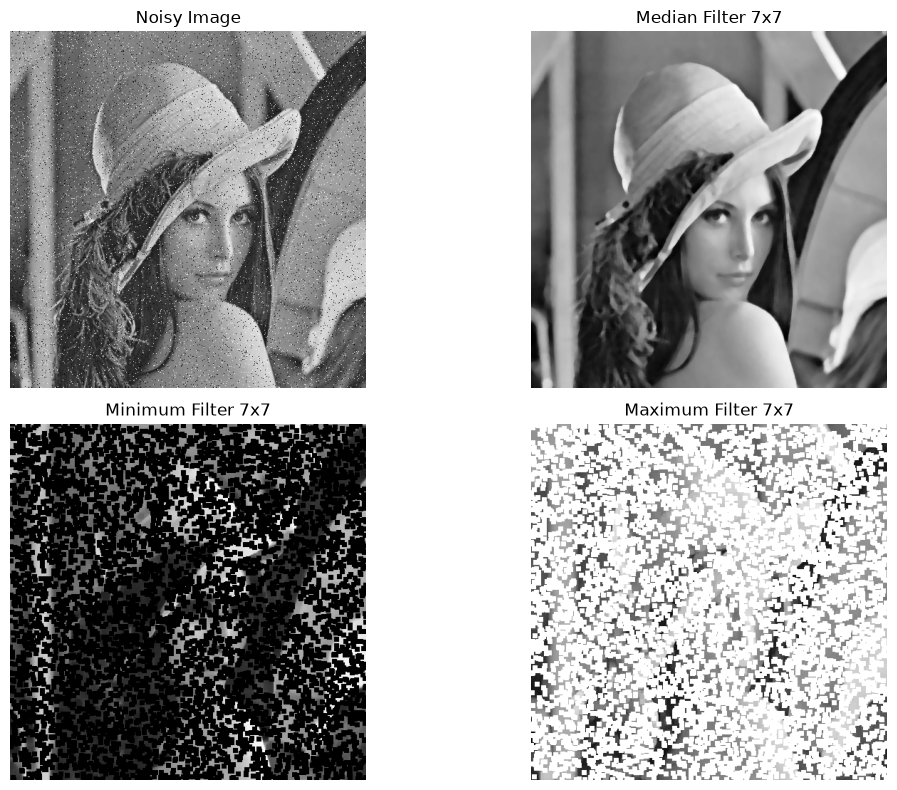

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# --------------------------------------------------
# Read image
# --------------------------------------------------

img = cv2.imread(
    "Lenna.png",
    cv2.IMREAD_GRAYSCALE
)

if img is None:
    print("Image not found!")
    exit()


# --------------------------------------------------
# Add salt-and-pepper noise
# --------------------------------------------------

def add_salt_pepper_noise(image, amount=0.05):

    noisy = image.copy()

    total = image.size
    n = int(total * amount)

    # Salt
    rows = np.random.randint(
        0,
        image.shape[0],
        n // 2
    )

    cols = np.random.randint(
        0,
        image.shape[1],
        n // 2
    )

    noisy[rows, cols] = 255

    # Pepper
    rows = np.random.randint(
        0,
        image.shape[0],
        n // 2
    )

    cols = np.random.randint(
        0,
        image.shape[1],
        n // 2
    )

    noisy[rows, cols] = 0

    return noisy


noisy = add_salt_pepper_noise(img)


# --------------------------------------------------
# Different kernel sizes
# --------------------------------------------------

for k in [3, 5, 7]:

    # Median filter
    median = cv2.medianBlur(
        noisy,
        k
    )

    # Minimum filter
    # Minimum filter = erosion with rectangular kernel
    kernel = np.ones(
        (k, k),
        np.uint8
    )

    minimum = cv2.erode(
        noisy,
        kernel
    )

    # Maximum filter
    # Maximum filter = dilation with rectangular kernel
    maximum = cv2.dilate(
        noisy,
        kernel
    )


    # --------------------------------------------------
    # Display
    # --------------------------------------------------

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(noisy, cmap="gray")
    plt.title("Noisy Image")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(median, cmap="gray")
    plt.title(f"Median Filter {k}x{k}")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(minimum, cmap="gray")
    plt.title(f"Minimum Filter {k}x{k}")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(maximum, cmap="gray")
    plt.title(f"Maximum Filter {k}x{k}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Session 6: Image Sharpening and Edge Detection

### Q1. Image sharpening using spatial-domain techniques

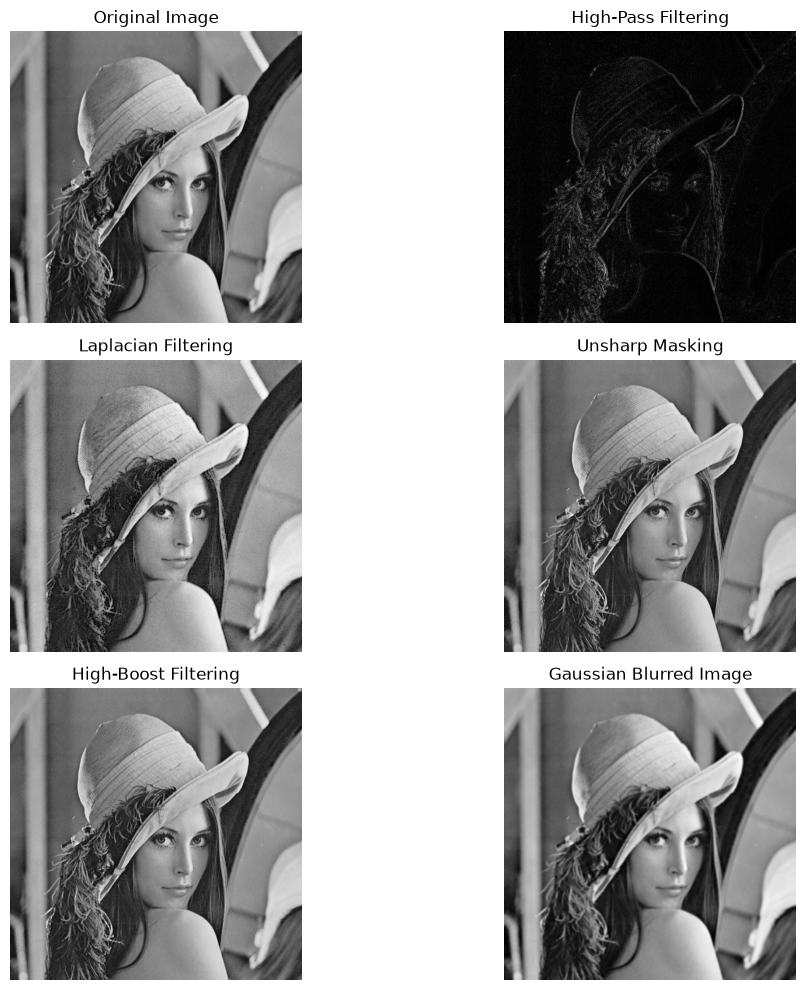

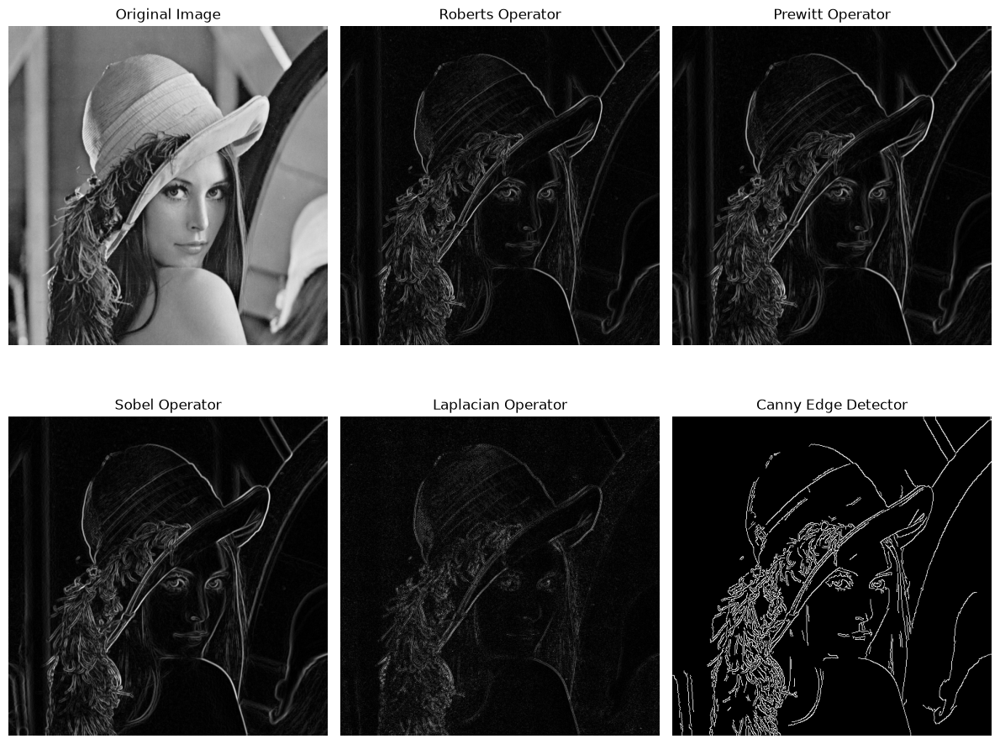

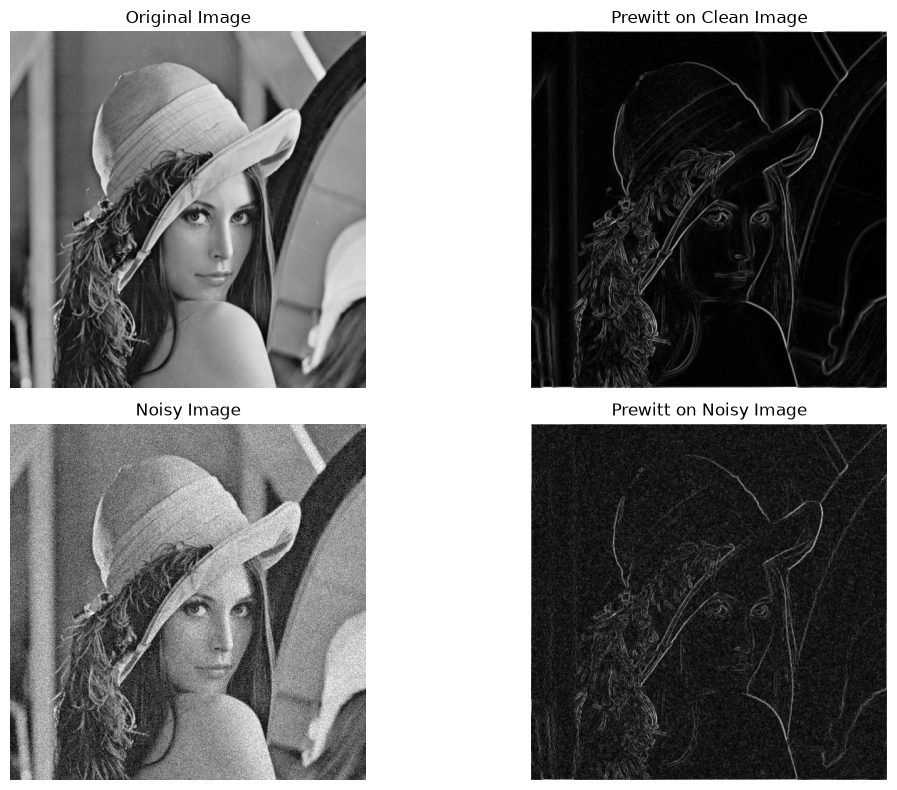

In [3]:
# --------------------------------------------------
# Read Image
# --------------------------------------------------

img = cv2.imread(
    "Lenna.png",
    cv2.IMREAD_GRAYSCALE
)

if img is None:
    print("Image not found!")
    raise SystemExit


# ==================================================
# Q1. IMAGE SHARPENING
# ==================================================


# --------------------------------------------------
# 1. High-Pass Filtering
# --------------------------------------------------

kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

high_pass = cv2.filter2D(
    img,
    cv2.CV_32F,
    kernel
)

high_pass = np.abs(high_pass)

high_pass = cv2.normalize(
    high_pass,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


# --------------------------------------------------
# 2. Laplacian Filtering
# --------------------------------------------------

laplacian = cv2.Laplacian(
    img,
    cv2.CV_64F
)

laplacian = cv2.convertScaleAbs(
    laplacian
)

laplacian_sharp = cv2.subtract(
    img,
    laplacian
)


# --------------------------------------------------
# 3. Unsharp Masking
# --------------------------------------------------

blurred = cv2.GaussianBlur(
    img,
    (5, 5),
    1
)

unsharp = cv2.addWeighted(
    img,
    1.5,
    blurred,
    -0.5,
    0
)


# --------------------------------------------------
# 4. High-Boost Filtering
# --------------------------------------------------

A = 1.5

high_boost = cv2.addWeighted(
    img,
    A,
    blurred,
    1 - A,
    0
)


# --------------------------------------------------
# Display Image Sharpening Results
# --------------------------------------------------

plt.figure(figsize=(12, 10))

plt.subplot(3, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(3, 2, 2)
plt.imshow(high_pass, cmap="gray")
plt.title("High-Pass Filtering")
plt.axis("off")

plt.subplot(3, 2, 3)
plt.imshow(laplacian_sharp, cmap="gray")
plt.title("Laplacian Filtering")
plt.axis("off")

plt.subplot(3, 2, 4)
plt.imshow(unsharp, cmap="gray")
plt.title("Unsharp Masking")
plt.axis("off")

plt.subplot(3, 2, 5)
plt.imshow(high_boost, cmap="gray")
plt.title("High-Boost Filtering")
plt.axis("off")

plt.subplot(3, 2, 6)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blurred Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# Q2. EDGE DETECTION
# ==================================================


# --------------------------------------------------
# 1. Roberts Operator
# --------------------------------------------------

roberts_x = np.array([
    [1,  0],
    [0, -1]
])

roberts_y = np.array([
    [0,  1],
    [-1, 0]
])

gx = cv2.filter2D(
    img,
    cv2.CV_32F,
    roberts_x
)

gy = cv2.filter2D(
    img,
    cv2.CV_32F,
    roberts_y
)

roberts = np.sqrt(
    gx**2 + gy**2
)

roberts = cv2.normalize(
    roberts,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


# --------------------------------------------------
# 2. Prewitt Operator
# --------------------------------------------------

prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

prewitt_y = np.array([
    [ 1,  1,  1],
    [ 0,  0,  0],
    [-1, -1, -1]
])

gx = cv2.filter2D(
    img,
    cv2.CV_32F,
    prewitt_x
)

gy = cv2.filter2D(
    img,
    cv2.CV_32F,
    prewitt_y
)

prewitt = np.sqrt(
    gx**2 + gy**2
)

prewitt = cv2.normalize(
    prewitt,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


# --------------------------------------------------
# 3. Sobel Operator
# --------------------------------------------------

sobel_x = cv2.Sobel(
    img,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)

sobel_y = cv2.Sobel(
    img,
    cv2.CV_64F,
    0,
    1,
    ksize=3
)

sobel = np.sqrt(
    sobel_x**2 + sobel_y**2
)

sobel = cv2.normalize(
    sobel,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


# --------------------------------------------------
# 4. Laplacian Operator
# --------------------------------------------------

laplacian_edge = cv2.Laplacian(
    img,
    cv2.CV_64F
)

laplacian_edge = cv2.convertScaleAbs(
    laplacian_edge
)


# --------------------------------------------------
# 5. Canny Edge Detector
# --------------------------------------------------

canny = cv2.Canny(
    img,
    100,
    200
)


# --------------------------------------------------
# Display Edge Detection Results
# --------------------------------------------------

plt.figure(figsize=(12, 10))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(roberts, cmap="gray")
plt.title("Roberts Operator")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(prewitt, cmap="gray")
plt.title("Prewitt Operator")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(sobel, cmap="gray")
plt.title("Sobel Operator")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(laplacian_edge, cmap="gray")
plt.title("Laplacian Operator")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(canny, cmap="gray")
plt.title("Canny Edge Detector")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# Q3. CHALLENGE: MANUAL PREWITT IMPLEMENTATION
# ==================================================


# --------------------------------------------------
# Add Gaussian Noise
# --------------------------------------------------

noise = np.random.normal(
    0,
    20,
    img.shape
)

noisy = img.astype(np.float32) + noise

noisy = np.clip(
    noisy,
    0,
    255
).astype(np.uint8)


# --------------------------------------------------
# Prewitt Kernels
# --------------------------------------------------

kernel_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

kernel_y = np.array([
    [ 1,  1,  1],
    [ 0,  0,  0],
    [-1, -1, -1]
])


# --------------------------------------------------
# Manual Prewitt Function
# --------------------------------------------------

def manual_prewitt(image):

    image = image.astype(np.float32)

    rows, cols = image.shape

    gx = np.zeros(
        (rows, cols),
        dtype=np.float32
    )

    gy = np.zeros(
        (rows, cols),
        dtype=np.float32
    )

    padded = np.pad(
        image,
        1,
        mode="constant"
    )

    # Apply convolution
    for i in range(1, rows + 1):

        for j in range(1, cols + 1):

            region = padded[
                i-1:i+2,
                j-1:j+2
            ]

            gx[i-1, j-1] = np.sum(
                region * kernel_x
            )

            gy[i-1, j-1] = np.sum(
                region * kernel_y
            )

    # Calculate edge magnitude
    result = np.sqrt(
        gx**2 + gy**2
    )

    result = cv2.normalize(
        result,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return result.astype(np.uint8)


# --------------------------------------------------
# Apply Manual Prewitt on Clean Image
# --------------------------------------------------

clean_edges = manual_prewitt(img)


# --------------------------------------------------
# Apply Manual Prewitt on Noisy Image
# --------------------------------------------------

noisy_edges = manual_prewitt(noisy)


# --------------------------------------------------
# Display Manual Prewitt Results
# --------------------------------------------------

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(clean_edges, cmap="gray")
plt.title("Prewitt on Clean Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(noisy, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(noisy_edges, cmap="gray")
plt.title("Prewitt on Noisy Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# Session 7: Frequency-Domain Image Enhancement

### Q1. Write a Python program to perform frequency-domain filtering using:

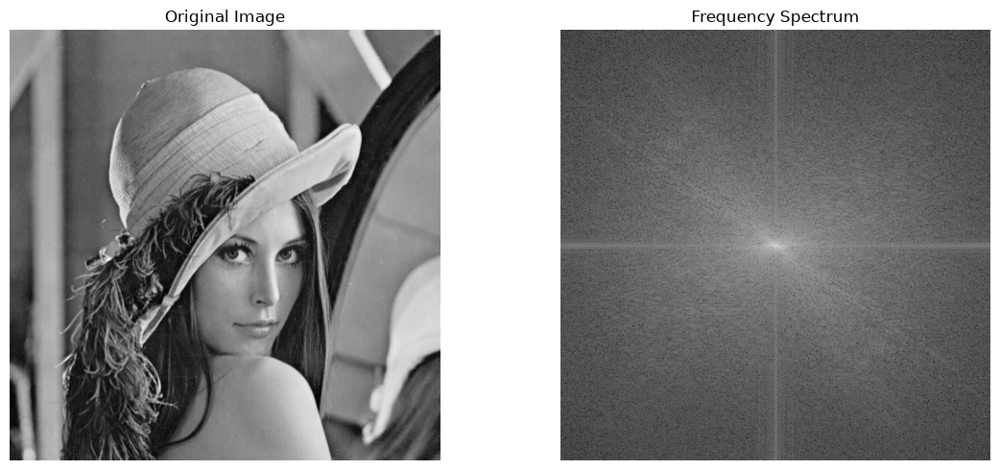

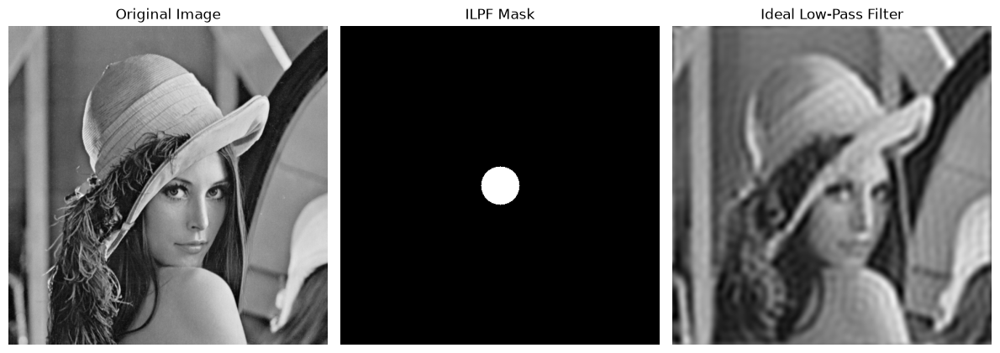

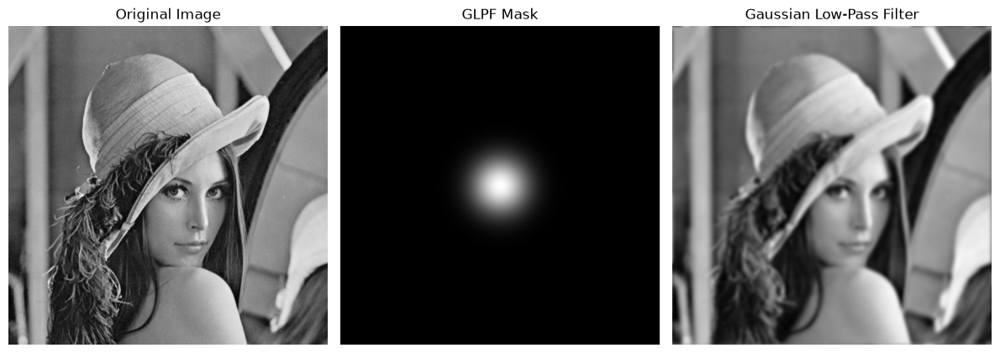

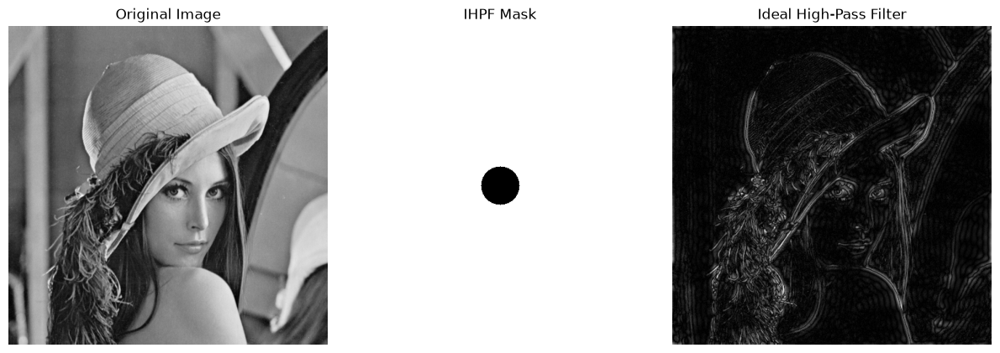

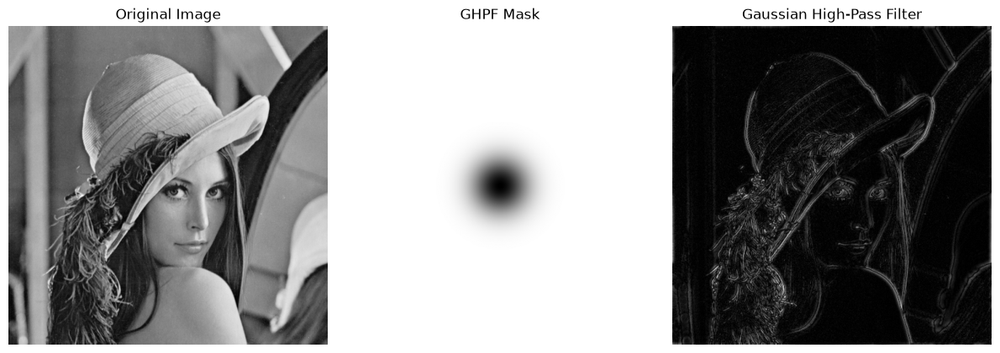

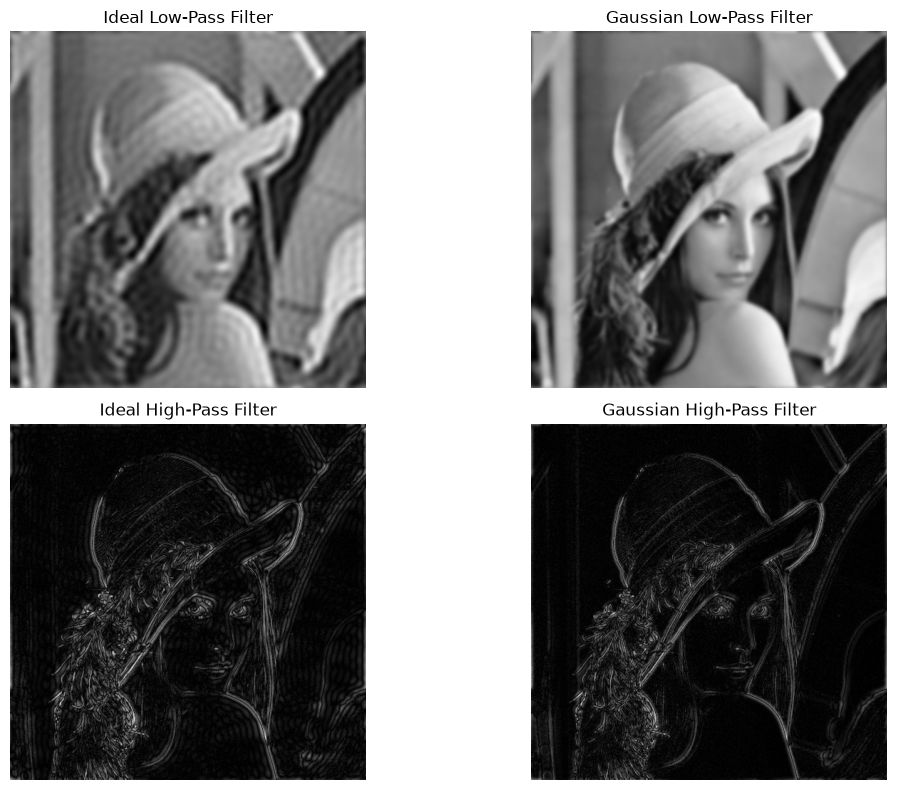

In [4]:
# --------------------------------------------------
# Read Image
# --------------------------------------------------

img = cv2.imread(
    "Lenna.png",
    cv2.IMREAD_GRAYSCALE
)

if img is None:
    print("Image not found!")
    raise SystemExit


# --------------------------------------------------
# Calculate DFT and Shift Spectrum
# --------------------------------------------------

dft = np.fft.fft2(img)

dft_shift = np.fft.fftshift(dft)


# --------------------------------------------------
# Display Original Image and Frequency Spectrum
# --------------------------------------------------

magnitude_spectrum = 20 * np.log(
    1 + np.abs(dft_shift)
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Frequency Spectrum")
plt.axis("off")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# Create Distance Matrix
# --------------------------------------------------

rows, cols = img.shape

crow = rows // 2
ccol = cols // 2

u = np.arange(rows).reshape(rows, 1)
v = np.arange(cols).reshape(1, cols)

D = np.sqrt(
    (u - crow)**2 + (v - ccol)**2
)

D0 = 30


# ==================================================
# Q1. IDEAL LOW-PASS FILTER (ILPF)
# ==================================================


# --------------------------------------------------
# Create Ideal Low-Pass Filter Mask
# --------------------------------------------------

ilpf_mask = np.zeros(
    (rows, cols),
    np.float32
)

ilpf_mask[D <= D0] = 1


# --------------------------------------------------
# Apply ILPF
# --------------------------------------------------

ilpf_dft = dft_shift * ilpf_mask

ilpf_inverse = np.fft.ifft2(
    np.fft.ifftshift(ilpf_dft)
)

ilpf_result = np.abs(
    ilpf_inverse
)


# --------------------------------------------------
# Display ILPF Results
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ilpf_mask, cmap="gray")
plt.title("ILPF Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ilpf_result, cmap="gray")
plt.title("Ideal Low-Pass Filter")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# Q2. GAUSSIAN LOW-PASS FILTER (GLPF)
# ==================================================


# --------------------------------------------------
# Create Gaussian Low-Pass Filter Mask
# --------------------------------------------------

glpf_mask = np.exp(
    -(D**2) / (2 * D0**2)
)


# --------------------------------------------------
# Apply GLPF
# --------------------------------------------------

glpf_dft = dft_shift * glpf_mask

glpf_inverse = np.fft.ifft2(
    np.fft.ifftshift(glpf_dft)
)

glpf_result = np.abs(
    glpf_inverse
)


# --------------------------------------------------
# Display GLPF Results
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(glpf_mask, cmap="gray")
plt.title("GLPF Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(glpf_result, cmap="gray")
plt.title("Gaussian Low-Pass Filter")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# Q3. IDEAL HIGH-PASS FILTER (IHPF)
# ==================================================


# --------------------------------------------------
# Create Ideal High-Pass Filter Mask
# --------------------------------------------------

ihpf_mask = np.ones(
    (rows, cols),
    np.float32
)

ihpf_mask[D <= D0] = 0


# --------------------------------------------------
# Apply IHPF
# --------------------------------------------------

ihpf_dft = dft_shift * ihpf_mask

ihpf_inverse = np.fft.ifft2(
    np.fft.ifftshift(ihpf_dft)
)

ihpf_result = np.abs(
    ihpf_inverse
)

ihpf_result = cv2.normalize(
    ihpf_result,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


# --------------------------------------------------
# Display IHPF Results
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ihpf_mask, cmap="gray")
plt.title("IHPF Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ihpf_result, cmap="gray")
plt.title("Ideal High-Pass Filter")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# Q4. GAUSSIAN HIGH-PASS FILTER (GHPF)
# ==================================================


# --------------------------------------------------
# Create Gaussian High-Pass Filter Mask
# --------------------------------------------------

ghpf_mask = 1 - np.exp(
    -(D**2) / (2 * D0**2)
)


# --------------------------------------------------
# Apply GHPF
# --------------------------------------------------

ghpf_dft = dft_shift * ghpf_mask

ghpf_inverse = np.fft.ifft2(
    np.fft.ifftshift(ghpf_dft)
)

ghpf_result = np.abs(
    ghpf_inverse
)

ghpf_result = cv2.normalize(
    ghpf_result,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


# --------------------------------------------------
# Display GHPF Results
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ghpf_mask, cmap="gray")
plt.title("GHPF Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ghpf_result, cmap="gray")
plt.title("Gaussian High-Pass Filter")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# FINAL COMPARISON OF ALL FOUR FILTERS
# ==================================================


plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(ilpf_result, cmap="gray")
plt.title("Ideal Low-Pass Filter")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(glpf_result, cmap="gray")
plt.title("Gaussian Low-Pass Filter")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(ihpf_result, cmap="gray")
plt.title("Ideal High-Pass Filter")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(ghpf_result, cmap="gray")
plt.title("Gaussian High-Pass Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

### Q2. Homomorphic Filtering

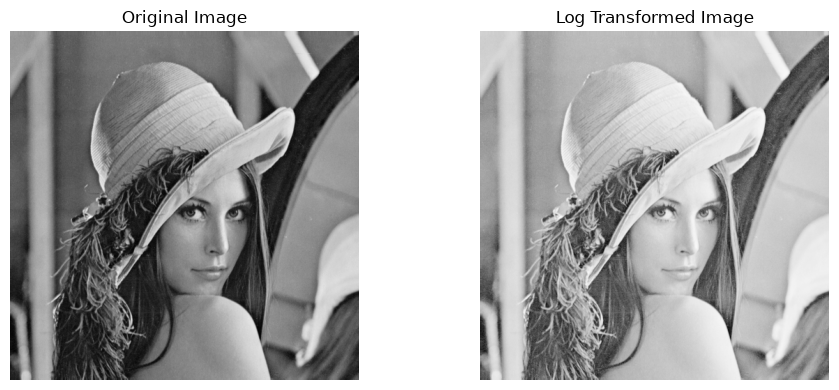

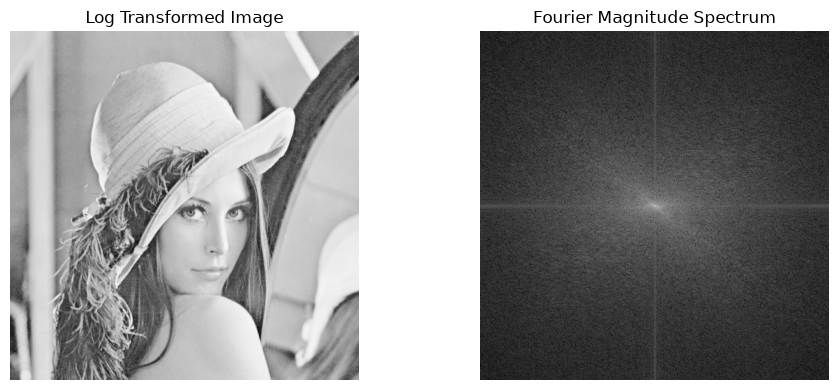

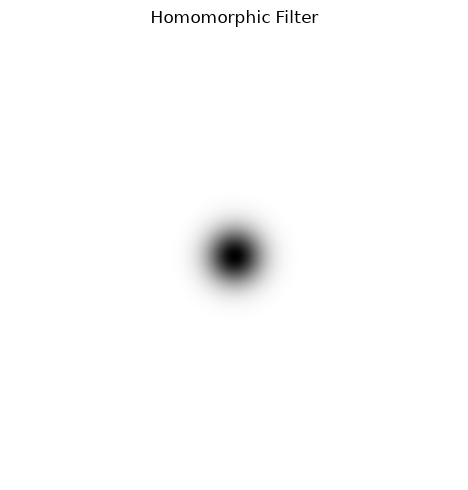

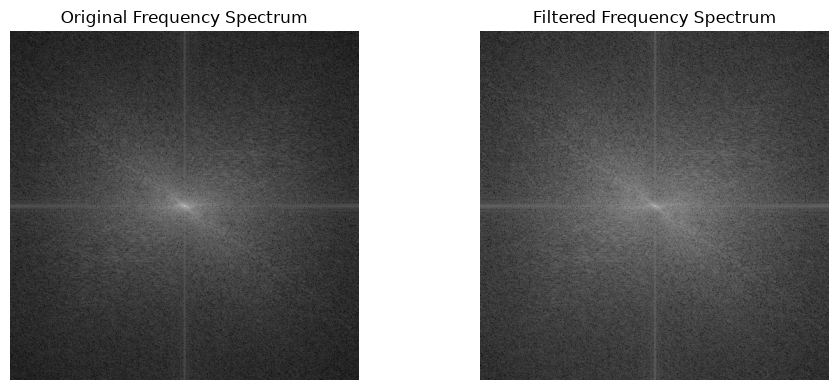

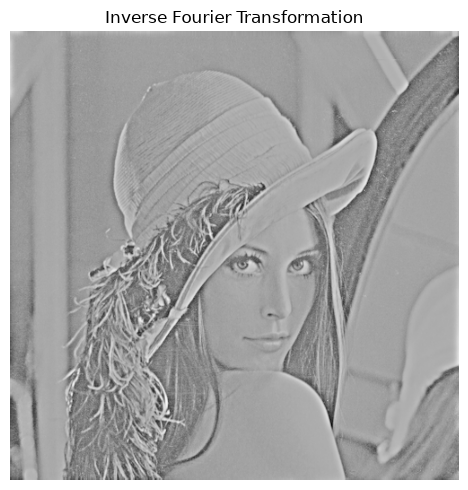

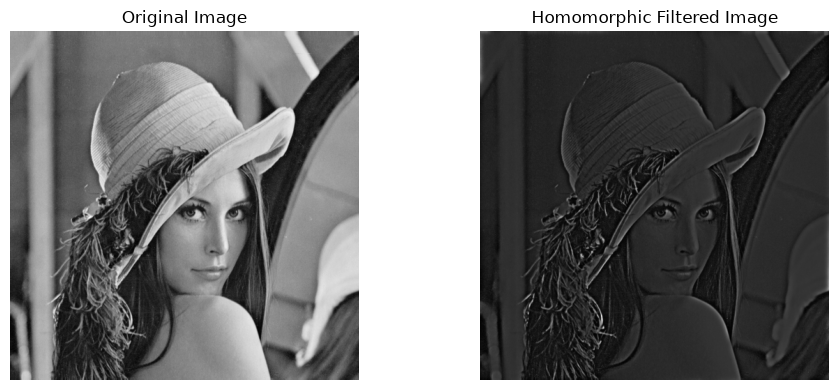

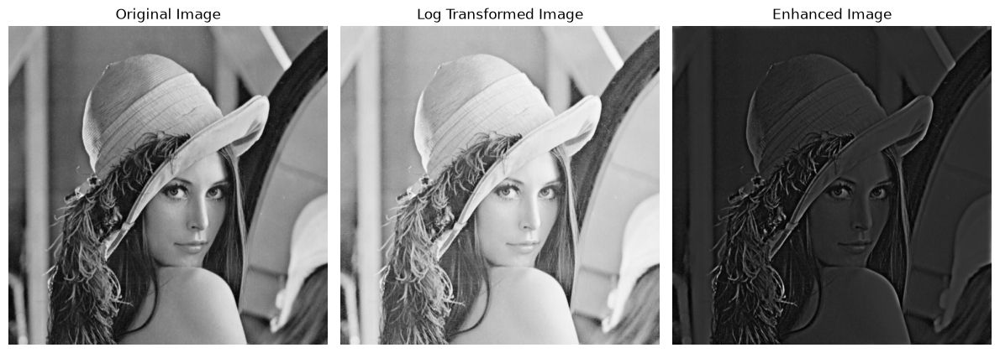

In [5]:
# --------------------------------------------------
# Read Image
# --------------------------------------------------

img = cv2.imread(
    "Lenna.png",
    cv2.IMREAD_GRAYSCALE
)

if img is None:
    print("Image not found!")
    raise SystemExit


# ==================================================
# STEP A. LOG TRANSFORMATION
# ==================================================


# --------------------------------------------------
# Apply Log Transformation
# --------------------------------------------------

img_float = img.astype(np.float32)

log_image = np.log1p(
    img_float
)


# --------------------------------------------------
# Display Log Transformed Image
# --------------------------------------------------

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(log_image, cmap="gray")
plt.title("Log Transformed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# STEP B. FOURIER TRANSFORMATION
# ==================================================


# --------------------------------------------------
# Calculate Fourier Transform
# --------------------------------------------------

dft = np.fft.fft2(
    log_image
)

dft_shift = np.fft.fftshift(
    dft
)


# --------------------------------------------------
# Calculate Magnitude Spectrum
# --------------------------------------------------

magnitude_spectrum = 20 * np.log(
    1 + np.abs(dft_shift)
)


# --------------------------------------------------
# Display Frequency Spectrum
# --------------------------------------------------

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(log_image, cmap="gray")
plt.title("Log Transformed Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Fourier Magnitude Spectrum")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# STEP C. CONSTRUCTION OF HOMOMORPHIC FILTER
# ==================================================


# --------------------------------------------------
# Create Distance Matrix
# --------------------------------------------------

rows, cols = img.shape

crow = rows // 2
ccol = cols // 2

u = np.arange(rows).reshape(rows, 1)
v = np.arange(cols).reshape(1, cols)

D = np.sqrt(
    (u - crow)**2 + (v - ccol)**2
)


# --------------------------------------------------
# Set Homomorphic Filter Parameters
# --------------------------------------------------

gamma_L = 0.5
gamma_H = 2.0
c = 1.0
D0 = 30


# --------------------------------------------------
# Construct Homomorphic Filter
# --------------------------------------------------

H = (gamma_H - gamma_L) * (
    1 - np.exp(-c * (D**2 / D0**2))
) + gamma_L


# --------------------------------------------------
# Display Homomorphic Filter
# --------------------------------------------------

plt.figure(figsize=(6, 5))

plt.imshow(H, cmap="gray")

plt.title("Homomorphic Filter")

plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# STEP D. FREQUENCY-DOMAIN FILTERING
# ==================================================


# --------------------------------------------------
# Apply Homomorphic Filter
# --------------------------------------------------

filtered_dft = dft_shift * H


# --------------------------------------------------
# Calculate Filtered Magnitude Spectrum
# --------------------------------------------------

filtered_spectrum = 20 * np.log(
    1 + np.abs(filtered_dft)
)


# --------------------------------------------------
# Display Filtered Spectrum
# --------------------------------------------------

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Original Frequency Spectrum")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(filtered_spectrum, cmap="gray")
plt.title("Filtered Frequency Spectrum")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# STEP E. INVERSE FOURIER TRANSFORMATION
# ==================================================


# --------------------------------------------------
# Apply Inverse Fourier Transform
# --------------------------------------------------

inverse_shift = np.fft.ifftshift(
    filtered_dft
)

inverse_dft = np.fft.ifft2(
    inverse_shift
)

inverse_image = np.real(
    inverse_dft
)


# --------------------------------------------------
# Display Inverse Fourier Result
# --------------------------------------------------

plt.figure(figsize=(6, 5))

plt.imshow(inverse_image, cmap="gray")

plt.title("Inverse Fourier Transformation")

plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# STEP F. EXPONENTIAL TRANSFORMATION
# ==================================================


# --------------------------------------------------
# Apply Exponential Transformation
# --------------------------------------------------

enhanced_image = np.exp(
    inverse_image
) - 1


# --------------------------------------------------
# Convert Enhanced Image to 8-bit
# --------------------------------------------------

enhanced_image = cv2.normalize(
    enhanced_image,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


# --------------------------------------------------
# Display Final Enhanced Image
# --------------------------------------------------

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_image, cmap="gray")
plt.title("Homomorphic Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==================================================
# FINAL COMPARISON
# ==================================================


plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(log_image, cmap="gray")
plt.title("Log Transformed Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(enhanced_image, cmap="gray")
plt.title("Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()